# seq2seq模型——机器翻译

### 案例简介

seq2seq是神经机器翻译的主流框架，如今的商用机器翻译系统大多都基于其构建，在本案例中，我们将使用由NIST提供的中英文本数据训练一个简单的中英翻译系统，在实践中学习seq2seq的具体细节，以及了解机器翻译的基本技术。

### seq2seq模型

从根本上讲，机器翻译需要将输入序列（源语言中的单词）映射到输出序列（目标语言中的单词）。正如我们在课堂上讨论的那样，递归神经网络（RNN）可有效处理此类顺序数据。机器翻译中的一个重要难题是输入和输出序列之间没有一对一的对应关系。即，序列通常具有不同的长度，并且单词对应可以是不平凡的（例如，彼此直接翻译的单词可能不会以相同的顺序出现）。

为了解决这个问题，我们将使用一种更灵活的架构，称为seq2seq模型。该模型由编码器和解码器两部分组成，它们都是RNN。编码器将源语言中的单词序列作为输入，并输出RNN层的最终隐藏状态。解码器与之类似，除了它还具有一个附加的全连接层（带有softmax激活），用于定义翻译中下一个单词的概率分布。以此方式，解码器本质上用作目标语言的神经语言模型。关键区别在于，解码器将编码器的输出用作其初始隐藏状态，而不是零向量。

### 数据和代码

本案例使用了一个小规模的中英平行语料数据，并提供了一个简单的seq2seq模型实现，包括数据的预处理、模型的训练、以及简单的评测。

### 评分要求

分数由两部分组成，各占50%。第一部分得分为对于简单seq2seq模型的改进，并撰写实验报告，改进方式多样，下一小节会给出一些可能的改进方向。第二分部得分为测试数据的评测结果，我们将给出一个中文测试数据集（`test.txt`），其中每一行为一句中文文本，需要同学提交模型做出的对应翻译结果，助教将对于大家的提交结果统一机器评测，并给出分数。

### 改进方向

初级改进：
- 将RNN模型替换成GRU或者LSTM
- 使用双向的encoder获得更好的源语言表示
- 对于现有超参数进行调优，这里建议划分出一个开发集，在开发集上进行grid search，并且在报告中汇报开发集结果
- 引入更多的训练语料（如果尝试复杂模型，更多的训练数据将非常关键）

进阶改进：
- 使用注意力机制（注意力机制是一个很重要的NMT技术，建议大家优先进行这方面的尝试，具体有许多种变体，可以参考这个[综述](https://nlp.stanford.edu/pubs/emnlp15_attn.pdf)）
- 在Encoder部分，使用了字级别的中文输入，可以考虑加入分词的结果，并且将Encoder的词向量替换为预训练过的词向量，获得更好的性能

复杂改进：
- 使用beam search的技术来帮助更好的解码，对于beam-width进行调优
- 将RNN替换为Transformer模型，以及最新的改进变体

## 环境依赖

In [1]:
import unicodedata
import string
import re
import random
import time
import math

import torch
import torch.nn as nn
from torch import optim
import torch.nn.functional as F

如果使用GPU，则将下面的变量设为`True`。

In [2]:
USE_CUDA = True

## 读取数据

我们将读取目录下的`cn-eng.txt`文件，其中每一行是一个平行句对，例子如下：

```
我很冷。    I am cold.
```

### 对于单词进行编号

这里引入了两个特殊符号，“SOS”即“Start of sentence”和“EOS”即“End of sentence”。他们会加到输入文本的两端，以控制解码过程。

In [3]:
'''
考虑了验证集/测试集未登录词(OOV)的处理，在此表中加入了未知词索引，并设置低频词过滤
对原代码做了相应改动
'''
SOS_token = 1  # 修改原索引 0（batch计算中0被用于padding）
EOS_token = 2  # 修改原索引 1（1被用于SOS索引）
UNK_token = 3  # 添加未知索引

class Lang:
    def __init__(self, name, min_count=1):
        self.name = name
        self.min_count = min_count
        # 特殊词索引（PAD=0 保留，但不一定使用）
        self.word2index = {"<SOS>": SOS_token, "<EOS>": EOS_token, "<UNK>": UNK_token}
        self.word2count = {}
        self.index2word = {SOS_token: "<SOS>", EOS_token: "<EOS>", UNK_token: "<UNK>"}
        self.n_words = 4   # 下一个新词索引从4开始

    def add_sentence(self, sentence):
        """先统计所有词的频率（不构建词表）"""
        if self.name == 'cn':
            words = list(sentence)
        else:
            words = sentence.split(' ')
        for w in words:
            self.word2count[w] = self.word2count.get(w, 0) + 1

    def finalize(self):
        """根据 min_count 过滤低频词，构建最终词表"""
        for w, cnt in self.word2count.items():
            if cnt >= self.min_count:
                if w not in self.word2index:
                    self.word2index[w] = self.n_words
                    self.index2word[self.n_words] = w
                    self.n_words += 1

    def indexes_from_sentence(self, sentence):
        """将句子转为索引，低频词/未知词替换为 UNK 索引"""
        if self.name == 'cn':
            words = list(sentence)
        else:
            words = sentence.split(' ')
        indexes = []
        for w in words:
            idx = self.word2index.get(w, self.word2index["<UNK>"])
            indexes.append(idx)
        return indexes

### 文本预处理

丢弃除了中文、字母和常用标点之外的符号。

In [4]:
# Turn a Unicode string to plain ASCII, thanks to http://stackoverflow.com/a/518232/2809427
def unicode_to_ascii(s):
    return ''.join(
        c for c in unicodedata.normalize('NFD', s)
        if unicodedata.category(c) != 'Mn'
    )

# Lowercase, trim, and remove non-letter characters
def normalize_string(s):
    s = unicode_to_ascii(s.lower().strip())
    s = re.sub(r"([.!?])", r" \1", s)
    s = re.sub(r"[^a-zA-Z\u4e00-\u9fa5.!?，。？]+", r" ", s)
    return s

读取平行语料，并进行清理。

In [5]:
def read_langs(lang1, lang2, reverse=False):
    print("Reading lines...")

    # Read the file and split into lines
    lines = open('%s-%s.txt' % (lang1, lang2), encoding='utf-8').read().strip().split('\n')
    
    # Split every line into pairs and normalize
    pairs = [[normalize_string(s) for s in l.split('\t')] for l in lines]
    
    # Reverse pairs, make Lang instances
    if reverse:
        pairs = [list(reversed(p)) for p in pairs]
        input_lang = Lang(lang2)
        output_lang = Lang(lang1)
    else:
        input_lang = Lang(lang1)
        output_lang = Lang(lang2)
        
    return input_lang, output_lang, pairs

### 过滤句子

样例为了加快训练，只保留了不长于10个单词的句对，真正实验中将更多数据考虑进来可能获得更好的效果。

In [6]:
MAX_LENGTH = 10

def filter_pair(p):
    return len(p[1].split(' ')) < MAX_LENGTH

def filter_pairs(pairs):
    return [pair for pair in pairs if filter_pair(pair)]

### 划分验证集

In [7]:
import numpy as np

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)  # 如果使用 GPU
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# 设置种子
set_seed(42)

In [8]:
def split_train_val(pairs, val_ratio=0.1):
    """
    将句子对拆分为训练集和验证集
    
    Args:
        pairs: 句子对列表，格式为[[src_sent, tgt_sent], ...]
        val_ratio: 验证集比例，默认0.2
        random_seed: 随机种子，默认42
    
    Returns:
        train_pairs: 训练集
        val_pairs: 验证集
    """
    random.shuffle(pairs)   # 现在 shuffle 结果固定（因已固定种子）

    total = len(pairs)
    train_split = total - int(total * val_ratio)   # 90% 训练

    train_pairs = pairs[:train_split]
    val_pairs = pairs[train_split:]

    print(f"总数据集大小: {len(pairs)}")
    print(f"训练集大小: {len(train_pairs)} ({len(train_pairs)/total:.1%})")
    print(f"验证集大小: {len(val_pairs)} ({len(val_pairs)/total:.1%})")
    
    return train_pairs, val_pairs

### 数据准备

处理数据的全过程：

- 读取数据，每一行分别处理，将其转换成句对
- 对于文本进行处理，过滤无用符号
- **数据集划分**
- 根据已有文本对于单词进行编号，构建符号到编号的映射


In [9]:
'''
词表类Lang中引入了<UNK>，词表构建方法也做相应修改
'''
def prepare_data(lang1_name, lang2_name, reverse=False, min_count=1):
    input_lang, output_lang, pairs = read_langs(lang1_name, lang2_name, reverse)
    print("Read %s sentence pairs" % len(pairs))

    pairs = filter_pairs(pairs)
    print("Trimmed to %s sentence pairs" % len(pairs))

    train_pairs, val_pairs = split_train_val(pairs)

    # 第一遍：统计词频（不构建词表）
    print("Counting words on train data...")
    for src, tgt in train_pairs:
        input_lang.add_sentence(src)
        output_lang.add_sentence(tgt)

    # 第二遍：根据 min_count 构建最终词表（低频词归为 UNK）
    print("Building vocabularies on train data(min_count=%d)..." % min_count)
    input_lang.finalize()
    output_lang.finalize()

    print("Input vocabulary size: %d" % input_lang.n_words)
    print("Output vocabulary size: %d" % output_lang.n_words)
    return input_lang, output_lang, train_pairs, val_pairs

input_lang, output_lang, train_pairs, val_pairs = prepare_data('cn', 'eng', reverse=False, min_count=2)
print(random.choice(train_pairs))

Reading lines...
Read 90000 sentence pairs
Trimmed to 68898 sentence pairs
总数据集大小: 68898
训练集大小: 62009 (90.0%)
验证集大小: 6889 (10.0%)
Counting words on train data...
Building vocabularies on train data(min_count=2)...
Input vocabulary size: 3883
Output vocabulary size: 8855
['她買了兩雙襪子。', 'she bought two pairs of socks .']


## 将文本数据转换为张量

为了训练，我们需要将句子变成神经网络可以理解的东西（数字）。每个句子将被分解成单词，然后变成张量，其中每个单词都被索引替换（来自之前的Lang索引）。在创建这些张量时，我们还将附加EOS令牌以表示该句子已结束。

![](https://i.imgur.com/LzocpGH.png)

In [10]:
'''
Lang类中加入了indexes_from_sentence方法
'''
# Return a list of indexes, one for each word in the sentence
# def indexes_from_sentence(lang, sentence):
#     if lang.name == 'cn':
#         return [lang.word2index[word] for word in sentence]
#     else:
#         return [lang.word2index[word] for word in sentence.split(' ')]

def variable_from_sentence(lang, sentence, add_batch_dim=False):
    """
    将句子转为模型输入张量
    Args:
        lang: Lang 实例
        sentence: 输入句子字符串
        add_batch_dim: 是否添加 batch 维度（即返回形状 (1, seq_len)）
    Returns:
        torch.LongTensor: 形状 (seq_len,) 或 (1, seq_len)
    """
    indexes = lang.indexes_from_sentence(sentence) + [EOS_token]
    tensor = torch.LongTensor(indexes)          # (seq_len,)
    if add_batch_dim:
        tensor = tensor.unsqueeze(0)            # (1, seq_len)
    if USE_CUDA: tensor = tensor.cuda()   
    return tensor

def variables_from_pair(pair):
    input_variable = variable_from_sentence(input_lang, pair[0])
    target_variable = variable_from_sentence(output_lang, pair[1])
    return (input_variable, target_variable)

# <font color=red>组件模型</font>

## <font color=red>编码器(双向GRU)</font>

In [11]:
class EncoderBiGRU(nn.Module):
    def __init__(self, input_size, hidden_size, n_layers=1):
        super().__init__()
        self.hidden_size = hidden_size
        self.n_layers = n_layers
        self.embedding = nn.Embedding(input_size, hidden_size)
        # 双向 GRU
        self.gru = nn.GRU(hidden_size, hidden_size, n_layers, bidirectional=True)
        
    def forward(self, word_inputs, hidden):
        # word_inputs: (seq_len,)
        seq_len = len(word_inputs)
        embedded = self.embedding(word_inputs).view(seq_len, 1, -1)  # (seq_len, 1, hidden)
        # 双向输出: (seq_len, 1, 2*hidden)
        output, hidden = self.gru(embedded, hidden)
        # hidden: (2*n_layers, 1, hidden) 双向各层
        return output, hidden

    def init_hidden(self):
        # 双向需要 2*n_layers 层
        hidden = torch.zeros(2 * self.n_layers, 1, self.hidden_size)
        if USE_CUDA: hidden = hidden.cuda()
        return hidden

## <font color=red>解码器(使用注意力机制的GRU)</font>

In [12]:
class DecoderAttnGRU(nn.Module):
    def __init__(self, hidden_size, output_size, n_layers=1, dropout_p=0.1):
        super(DecoderAttnGRU, self).__init__()
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.n_layers = n_layers
        self.dropout_p = dropout_p

        self.embedding = nn.Embedding(output_size, hidden_size)
        self.gru = nn.GRU(hidden_size, hidden_size, n_layers, dropout=dropout_p)
        # 注意力：将 rnn_output (hidden) 映射到与编码器输出相同维度 (hidden * 2)
        self.attn_linear = nn.Linear(hidden_size, hidden_size * 2)
        # 输出层：将 GRU 输出和上下文向量拼接
        self.out = nn.Linear(hidden_size * 3, output_size)
        self.dropout = nn.Dropout(dropout_p)

    def forward(self, word_input, last_hidden, encoder_outputs):
        # word_input: (1, batch)  例如 (1,1)
        # last_hidden: (n_layers, batch, hidden)
        # encoder_outputs: (seq_len, batch, hidden*2)

        batch_size = word_input.size(1)
        seq_len = encoder_outputs.size(0)

        # 1. 嵌入当前输入
        word_embedded = self.embedding(word_input)           # (1, batch, hidden)
        word_embedded = self.dropout(word_embedded)

        # 2. GRU 前向
        rnn_output, hidden = self.gru(word_embedded, last_hidden)   # rnn_output: (1, batch, hidden)

        # 3. 注意力计算 (Luong general)
        # 将 rnn_output 线性映射到 hidden*2 维
        rnn_proj = self.attn_linear(rnn_output)              # (1, batch, hidden*2)
        # 计算点积注意力分数 (batch, seq_len)
        # encoder_outputs: (seq_len, batch, hidden*2) -> 转置 (batch, seq_len, hidden*2)
        # rnn_proj: (1, batch, hidden*2) -> 转置 (batch, hidden*2, 1)
        attn_weights = torch.bmm(encoder_outputs.transpose(0, 1),    # (batch, seq_len, hidden*2)
                                 rnn_proj.transpose(0, 1).transpose(1, 2))  # (batch, hidden*2, 1)
        attn_weights = attn_weights.squeeze(2)                # (batch, seq_len)
        attn_weights = F.softmax(attn_weights, dim=1)         # 归一化

        # 上下文向量: (batch, 1, hidden*2)
        context = torch.bmm(attn_weights.unsqueeze(1), encoder_outputs.transpose(0, 1))
        # context 形状: (batch, 1, hidden*2)

        # 4. 拼接 GRU 输出和上下文，产生最终输出
        rnn_output = rnn_output.squeeze(0)                    # (batch, hidden)
        context = context.squeeze(1)                          # (batch, hidden*2)
        concat = torch.cat((rnn_output, context), dim=1)      # (batch, hidden + hidden*2) = (batch, hidden*3)
        # 注意：一般论文中只使用 hidden 和 context，但 hidden*2 + hidden = hidden*3。这里简化，直接线性映射到输出。
        output = self.out(concat)                             # (batch, output_size)
        output = F.log_softmax(output, dim=1)

        return output, hidden

# 训练

## 一次训练迭代

为了训练，我们首先通过编码器逐字运行输入语句，并跟踪每个输出和最新的隐藏状态。接下来，为解码器提供解码器的最后一个隐藏状态作为其第一隐藏状态，并向其提供`<SOS>`作为其第一输入。从那里开始，我们迭代地预测来自解码器的下一个单词。
    
### Teacher Forcing 和 Scheduled Sampling

"Teacher Forcing"指的是每次都基于完全准确的上文进行解码，这样训练模型收敛很快，但是会造成实际场景和训练场景有较大差别，因为实际场景上文也都是模型预测的，可能不准确，具体细节可参考[论文](http://minds.jacobs-university.de/sites/default/files/uploads/papers/ESNTutorialRev.pdf)。

观察Teacher Forcing的网络的输出，我们可以看到该网络语法连贯，但是偏离正确的翻译。可以将其为学会了如何听老师的指示，而未学习如何独自冒险。

解决强迫教师问题的方法称为“计划抽样”（[Scheduled Sampling](https://arxiv.org/abs/1506.03099)），它在训练时仅在使用目标值和预测值之间进行切换。我们将在训练时随机选择,有时我们将使用真实目标作为输入（忽略解码器的输出），有时我们将使用解码器的输出。

In [13]:
teacher_forcing_ratio = 0.5
clip = 5.0

def train(input_variable, target_variable, encoder, decoder, 
          encoder_optimizer, decoder_optimizer, criterion, max_length=MAX_LENGTH):
    encoder_optimizer.zero_grad()
    decoder_optimizer.zero_grad()
    loss = 0
    input_length = input_variable.size(0)          # (seq_len,)
    target_length = target_variable.size(0)        # (target_len,)

    # 1. 编码器前向（双向 GRU）
    encoder_hidden = encoder.init_hidden()          # (n_layers*2, 1, hidden)
    encoder_outputs, encoder_hidden = encoder(input_variable, encoder_hidden)
    # encoder_outputs: (seq_len, 1, hidden*2)
    # encoder_hidden: (n_layers*2, 1, hidden)

    # 2. 将双向编码器的最终隐藏状态转换为解码器需要的初始隐藏状态（单向 GRU）
    # 方法：取最后两层（前向和后向）并求和，然后重复 n_layers 次
    # 假设 decoder.n_layers == encoder.n_layers
    decoder_hidden = encoder_hidden[-2:, :, :].sum(dim=0, keepdim=True)  # (1, 1, hidden)
    decoder_hidden = decoder_hidden.repeat(decoder.n_layers, 1, 1)       # (n_layers, 1, hidden)

    # 3. 解码器初始输入
    decoder_input = torch.LongTensor([[SOS_token]])   # (1,1)
    if USE_CUDA:
        decoder_input = decoder_input.cuda()
        decoder_hidden = decoder_hidden.cuda()

    use_teacher_forcing = random.random() < teacher_forcing_ratio
    decoded_steps = 0

    if use_teacher_forcing:
        for di in range(target_length):
            decoder_output, decoder_hidden = decoder(decoder_input, decoder_hidden, encoder_outputs)
            loss += criterion(decoder_output, target_variable[di].view(1))
            decoder_input = target_variable[di].view(1, 1)
            decoded_steps += 1
    else:
        for di in range(target_length):
            decoder_output, decoder_hidden = decoder(decoder_input, decoder_hidden, encoder_outputs)
            loss += criterion(decoder_output, target_variable[di].view(1))
            topv, topi = decoder_output.topk(1)
            ni = topi[0, 0].item()
            decoder_input = torch.LongTensor([[ni]])
            if USE_CUDA:
                decoder_input = decoder_input.cuda()
            decoded_steps += 1
            if ni == EOS_token:
                break

    loss.backward()
    torch.nn.utils.clip_grad_norm_(encoder.parameters(), clip)
    torch.nn.utils.clip_grad_norm_(decoder.parameters(), clip)
    encoder_optimizer.step()
    decoder_optimizer.step()

    return loss.item() / decoded_steps if decoded_steps > 0 else 0

下面是用于辅助输出训练情况的函数

In [14]:
def as_minutes(s):
    m = math.floor(s / 60)
    s -= m * 60
    return '%dm %ds' % (m, s)

def time_since(since, percent):
    now = time.time()
    s = now - since
    es = s / (percent)
    rs = es - s
    return '%s (- %s)' % (as_minutes(s), as_minutes(rs))

## 进行训练

In [15]:
hidden_size = 256
n_layers = 2
dropout_p = 0.05

# Initialize models
encoder = EncoderBiGRU(input_lang.n_words, hidden_size, n_layers)
decoder = DecoderAttnGRU(hidden_size, output_lang.n_words, n_layers, dropout_p=dropout_p)

# Move models to GPU
if USE_CUDA:
    encoder.cuda()
    decoder.cuda()

# Initialize optimizers and criterion
learning_rate = 0.0001
encoder_optimizer = optim.Adam(encoder.parameters(), lr=learning_rate)
decoder_optimizer = optim.Adam(decoder.parameters(), lr=learning_rate)
criterion = nn.NLLLoss()

以下设置变量用于绘制图标和跟踪进度：

In [16]:
# Configuring training
n_epochs = 50000
plot_every = 200
print_every = 1000

# Keep track of time elapsed and running averages
start = time.time()
plot_losses = []
print_loss_total = 0 # Reset every print_every
plot_loss_total = 0 # Reset every plot_every

要进行实际训练，我们会多次调用训练函数，并在进行过程中打印中间信息。

In [17]:
# Begin!
for epoch in range(1, n_epochs + 1):
    
    # Get training data for this cycle
    training_pair = variables_from_pair(random.choice(train_pairs))
    input_variable = training_pair[0]
    target_variable = training_pair[1]

    # Run the train function
    loss = train(input_variable, target_variable, encoder, decoder, encoder_optimizer, decoder_optimizer, criterion)

    # Keep track of loss
    print_loss_total += loss
    plot_loss_total += loss

    if epoch == 0: continue

    if epoch % print_every == 0:
        print_loss_avg = print_loss_total / print_every
        print_loss_total = 0
        print_summary = '%s (%d %d%%) %.4f' % (time_since(start, epoch / n_epochs), epoch, epoch / n_epochs * 100, print_loss_avg)
        print(print_summary)

    if epoch % plot_every == 0:
        plot_loss_avg = plot_loss_total / plot_every
        plot_losses.append(plot_loss_avg)
        plot_loss_total = 0

0m 41s (- 33m 37s) (1000 2%) 6.0907
1m 19s (- 31m 52s) (2000 4%) 5.2000
1m 58s (- 30m 49s) (3000 6%) 4.8677
2m 36s (- 30m 2s) (4000 8%) 4.7097
3m 15s (- 29m 21s) (5000 10%) 4.6065
3m 54s (- 28m 43s) (6000 12%) 4.4105
4m 35s (- 28m 13s) (7000 14%) 4.4646
5m 16s (- 27m 42s) (8000 16%) 4.3999
5m 57s (- 27m 6s) (9000 18%) 4.3767
6m 37s (- 26m 31s) (10000 20%) 4.2359
7m 19s (- 25m 58s) (11000 22%) 4.0725
8m 0s (- 25m 20s) (12000 24%) 4.1033
8m 41s (- 24m 45s) (13000 26%) 3.9553
9m 23s (- 24m 8s) (14000 28%) 3.9418
10m 4s (- 23m 30s) (15000 30%) 3.9092
10m 45s (- 22m 52s) (16000 32%) 3.8853
11m 27s (- 22m 13s) (17000 34%) 3.7617
12m 8s (- 21m 35s) (18000 36%) 3.8246
12m 48s (- 20m 54s) (19000 38%) 3.6850
13m 28s (- 20m 12s) (20000 40%) 3.7198
14m 7s (- 19m 29s) (21000 42%) 3.6900
14m 46s (- 18m 47s) (22000 44%) 3.5907
15m 25s (- 18m 6s) (23000 46%) 3.5359
16m 5s (- 17m 25s) (24000 48%) 3.5267
16m 44s (- 16m 44s) (25000 50%) 3.4515
17m 22s (- 16m 2s) (26000 52%) 3.4088
18m 1s (- 15m 21s) (270

## 绘制训练loss

<Figure size 640x480 with 0 Axes>

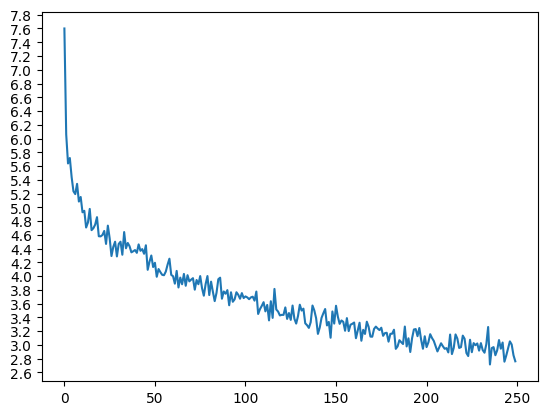

In [18]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
%matplotlib inline

def show_plot(points):
    plt.figure()
    fig, ax = plt.subplots()
    loc = ticker.MultipleLocator(base=0.2) # put ticks at regular intervals
    ax.yaxis.set_major_locator(loc)
    plt.plot(points)

show_plot(plot_losses)

# 模型验证

In [21]:
def evaluate(sentence, max_length=MAX_LENGTH):
    # 1. 输入张量 (seq_len,)
    input_variable = variable_from_sentence(input_lang, sentence)
    if USE_CUDA:
        input_variable = input_variable.cuda()

    # 2. 编码器（双向）
    encoder_hidden = encoder.init_hidden()          # (n_layers*2, 1, hidden)
    encoder_outputs, encoder_hidden = encoder(input_variable, encoder_hidden)

    # 3. 转换解码器初始隐藏状态（双向 -> 单向）
    # 取最后两层（前向和后向）并求和，然后重复解码器层数次
    decoder_hidden = encoder_hidden[-2:, :, :].sum(dim=0, keepdim=True)  # (1, 1, hidden)
    decoder_hidden = decoder_hidden.repeat(decoder.n_layers, 1, 1)        # (n_layers, 1, hidden)

    # 4. 解码器初始输入
    decoder_input = torch.LongTensor([[SOS_token]])   # (1,1)
    if USE_CUDA:
        decoder_input = decoder_input.cuda()

    decoded_words = []
    for di in range(max_length):
        # 注意：解码器需要传入 encoder_outputs
        decoder_output, decoder_hidden = decoder(decoder_input, decoder_hidden, encoder_outputs)
        topv, topi = decoder_output.topk(1)
        ni = topi[0, 0].item()
        if ni == EOS_token:
            break
        else:
            decoded_words.append(output_lang.index2word[ni])
        decoder_input = torch.LongTensor([[ni]])
        if USE_CUDA:
            decoder_input = decoder_input.cuda()

    # 5. 过滤特殊标记，返回字符串
    filtered_words = [w for w in decoded_words if w not in ('<EOS>', '<SOS>', '<PAD>')]
    return ' '.join(filtered_words)

随机选取一个句子进行验证。

In [22]:
def evaluate_randomly(pairs):
    pair = random.choice(pairs)
    
    output_sentence = evaluate(pair[0])
    
    print('>', pair[0])
    print('=', pair[1])
    print('<', output_sentence)
    print('')

print("====== 随机训练集 ======")
evaluate_randomly(train_pairs)

print("\n====== 随机验证集 ======")
evaluate_randomly(val_pairs)

====== 随机训练集 ======
> 我们的花园布满了杂草。
= our garden was full of weeds .
< our garden are full in the .


====== 随机验证集 ======
> 他的話讓我吃驚。
= his words surprised me .
< his words me me .



**用验证集计算BLEU：**

In [23]:
from nltk.translate.bleu_score import sentence_bleu, corpus_bleu
from nltk.translate.bleu_score import SmoothingFunction
import numpy as np

def calculate_bleu(references, hypotheses):
    """
    计算BLEU分数
    
    Args:
        references: 参考译文列表，每个元素是参考句子的分词列表
        hypotheses: 模型预测的译文列表，每个元素是预测句子的分词列表
    """
    # 使用平滑函数处理短句子
    smoothie = SmoothingFunction().method4
    
    # 计算句子级别的BLEU
    sentence_bleu_scores = []
    for ref, hyp in zip(references, hypotheses):
        # 注意：sentence_bleu的reference需要是列表的列表
        score = sentence_bleu([ref], hyp, 
                              weights=(0.25, 0.25, 0.25, 0.25),
                              smoothing_function=smoothie)
        sentence_bleu_scores.append(score)
    
    # 计算语料库级别的BLEU
    corpus_bleu_score = corpus_bleu([[ref] for ref in references], 
                                    hypotheses,
                                    smoothing_function=smoothie)
    
    return {
        'corpus_bleu': corpus_bleu_score,
        'mean_sentence_bleu': np.mean(sentence_bleu_scores),
        'sentence_bleus': sentence_bleu_scores
    }

In [24]:
references = [pair[1] for pair in val_pairs]  # 参考译文
hypotheses = [evaluate(pair[0]) for pair in val_pairs]  # 模型预测    

bleu_scores = calculate_bleu(references, hypotheses)
print(f"Corpus BLEU: {bleu_scores['corpus_bleu']:.4f}")
print(f"Avarage Sentence BLEU: {bleu_scores['mean_sentence_bleu']:.4f}")

Corpus BLEU: 0.4123
Avarage Sentence BLEU: 0.3983


In [30]:
for i in range(5):
    print(f"参考原文: {val_pairs[i][1]}")
    print(f"参考分词: {references[i]}")
    print(f"假设分词: {hypotheses[i]}")
    print()

参考原文: i thought tom would enjoy the party .
参考分词: i thought tom would enjoy the party .
假设分词: i thought tom would like this . .

参考原文: caution wet floor
参考分词: caution wet floor
假设分词: be your .

参考原文: you cannot do this .
参考分词: you cannot do this .
假设分词: you can t do this . .

参考原文: james was caught in a shower .
参考分词: james was caught in a shower .
假设分词: tom has on the the . .

参考原文: i wasn t yelling .
参考分词: i wasn t yelling .
假设分词: i don t have a . .



In [25]:
def translate_file(encoder, decoder, input_file, output_file):
    """
    读取txt文件中的原文，批量翻译，保存原文和翻译结果
    
    Args:
        encoder: 编码器模型
        decoder: 解码器模型
        input_file: 输入的原文文件路径
        output_file: 输出的翻译结果文件路径
    """
    
    print("=" * 70)
    print("文件批量翻译")
    print("=" * 70)
    
    # 1. 读取所有句子
    with open(input_file, 'r', encoding='utf-8') as f:
        all_sentences = [normalize_string(line).strip() for line in f if line.strip()]
    
    print(f"\n📖 读取到 {len(all_sentences)} 个句子")
    
    # # 2. 筛选有效句子
    # valid_sentences = []
    # original_sentences = []
    # skipped_indices = []
    
    # print("\n🔍 检查词汇表...")
    # for i, sentence in enumerate(all_sentences):
    #     if is_sentence_valid(input_lang, sentence):
    #         valid_sentences.append(sentence)
    #     else:
    #         skipped_indices.append(i)
    #         # print(f"  跳过句子 {i+1}: '{sentence}'")
    
    # # 3. 打印统计
    # print(f"\n📊 统计结果:")
    # print(f"  总句子数: {len(all_sentences)}")
    # print(f"  有效句子: {len(valid_sentences)}")
    # print(f"  跳过句子: {len(skipped_indices)}")
    
    # if len(valid_sentences) == 0:
    #     print("\n❌ 没有有效句子可翻译！")
    #     return [], len(skipped_indices)
    
    # 4. 批量翻译
    print(f"\n🔄 开始翻译...")
    start_time = time.time()
    
    translations = []
    for sentence in all_sentences:
        output_words = evaluate(sentence)
        output_sentence = ' '.join([w for w in output_words if w not in ('<EOS>', '<SOS>', '<PAD>')])
        translations.append(output_sentence)
        
    
    elapsed_time = time.time() - start_time
    print(f"✅ 翻译完成！用时: {elapsed_time:.2f} 秒")
    print(f"   平均每句: {elapsed_time/len(all_sentences):.3f} 秒")
    
    # 5. 保存结果
    print(f"\n💾 保存翻译结果到: {output_file}")
    
    with open(output_file, 'w', encoding='utf-8') as f:
        # 写入翻译结果
        for src, trans in zip(all_sentences, translations):
            f.write(f"{src}\t{trans}\n")
    
    print(f"✅ 成功保存 {len(translations)} 条翻译结果")

    # # 6. 可选：保存跳过的句子到单独文件
    # if skipped_indices:
    #     skipped_file = output_file.replace('.txt', '_skipped.txt')
    #     with open(skipped_file, 'w', encoding='utf-8') as f:
    #         for idx in skipped_indices:
    #             f.write(f"{all_sentences[idx]}\n")
    #     print(f"  跳过的句子已保存到: {skipped_file}")
    
    # 7. 显示翻译预览
    print("\n📝 翻译预览 (前5行):")
    for i, (src, trans) in enumerate(zip(all_sentences[:5], translations[:5])):
        print(f"  {i+1}. {src} -> {trans}")
    
    print("\n" + "=" * 70)
    print(f"处理完成！")
    print(f"输入文件: {input_file}")
    print(f"输出文件: {output_file}")
    print("=" * 70)
    
    return
    

In [26]:
INPUT_FILE='test.txt'
OUTPUT_FILE='test_translations_attn.txt'

translate_file(encoder, decoder, input_file=INPUT_FILE, output_file=OUTPUT_FILE)

文件批量翻译

📖 读取到 9688 个句子

🔄 开始翻译...
✅ 翻译完成！用时: 126.50 秒
   平均每句: 0.013 秒

💾 保存翻译结果到: test_translations_attn.txt
✅ 成功保存 9688 条翻译结果

📝 翻译预览 (前5行):
  1. 為什麼我一直學不好英語？ -> w h y   d i d   i   h a v e   a   e n g l i s h   e n g l i s h   ?
  2. 她讓我坐在她的身邊。 -> s h e   m a d e   m e   t o   h e r   h e r   .   .
  3. 這瓶酸奶不含乳糖。 -> t h i s   m i l k   i s   n o t   f r o m   t h e   .   .
  4. 這瓶酸奶不含乳糖。 -> t h i s   m i l k   i s   n o t   f r o m   t h e   .   .
  5. 我不能幫你了。 -> i   c a n   t   h e l p   y o u   .

处理完成！
输入文件: test.txt
输出文件: test_translations_attn.txt


# 批处理
**之前的训练代码中，每一个epoch只是随机选择了一个句子对进行训练学习。$n\_epochs = 50000$实际上并不是50000轮完整的数据集训练，而是50000次迭代，数据集没有被充分利用。**

**采用批处理，在每一轮训练中遍历所有训练集数据对。**

#### 1. 修正编码器/解码器以支持批处理

In [11]:
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

class EncoderBiGRU(nn.Module):
    def __init__(self, input_size, hidden_size, n_layers=1, dropout=0.1):
        super().__init__()
        self.hidden_size = hidden_size
        self.n_layers = n_layers
        self.embedding = nn.Embedding(input_size, hidden_size)
        self.gru = nn.GRU(hidden_size, hidden_size, n_layers,
                          bidirectional=True, dropout=dropout if n_layers > 1 else 0,
                          batch_first=True)  # 添加 batch_first=True
        self.dropout = nn.Dropout(dropout)

    def forward(self, input_seq, input_lengths, hidden=None):
        # input_seq: (batch, seq_len)
        embedded = self.dropout(self.embedding(input_seq))  # (batch, seq_len, hidden)
        packed = pack_padded_sequence(embedded, input_lengths.cpu(), batch_first=True, enforce_sorted=False)
        outputs, hidden = self.gru(packed, hidden)
        outputs, _ = pad_packed_sequence(outputs, batch_first=True)  # (batch, max_seq_len, hidden*2)
        return outputs, hidden

    def init_hidden(self, batch_size):
        hidden = torch.zeros(self.n_layers * 2, batch_size, self.hidden_size)
        if USE_CUDA:
            hidden = hidden.cuda()
        return hidden

In [12]:
class DecoderAttnGRU(nn.Module):
    def __init__(self, hidden_size, output_size, n_layers=1, dropout=0.1):
        super().__init__()
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.n_layers = n_layers

        self.embedding = nn.Embedding(output_size, hidden_size)
        self.gru = nn.GRU(hidden_size, hidden_size, n_layers,
                          dropout=dropout, batch_first=True)   # batch_first=True
        self.attn_linear = nn.Linear(hidden_size, hidden_size * 2)
        self.out = nn.Linear(hidden_size * 3, output_size)     # hidden + hidden*2 = hidden*3
        self.dropout = nn.Dropout(dropout)

    def forward(self, word_input, last_hidden, encoder_outputs, encoder_lengths=None):
        """
        word_input: (batch, 1)
        last_hidden: (n_layers, batch, hidden)  单向
        encoder_outputs: (batch, src_len, hidden*2)
        """
        batch_size = word_input.size(0)
        # 嵌入 (batch, 1, hidden)
        word_embedded = self.embedding(word_input)
        word_embedded = self.dropout(word_embedded)

        # GRU 前向 (输入形状 (batch, 1, hidden)，输出 (batch, 1, hidden))
        rnn_output, hidden = self.gru(word_embedded, last_hidden)   # (batch, 1, hidden)

        # 注意力分数 (batch, src_len)
        rnn_proj = self.attn_linear(rnn_output)   # (batch, 1, hidden*2)
        # 计算点积
        scores = torch.bmm(encoder_outputs, rnn_proj.transpose(1, 2))  # (batch, src_len, 1)
        scores = scores.squeeze(2)                # (batch, src_len)
            
        if encoder_lengths is not None:
            # 将 encoder_lengths 移动到与 scores 相同的设备
            encoder_lengths = encoder_lengths.to(scores.device)
            mask = torch.arange(encoder_outputs.size(1), device=scores.device) < encoder_lengths.unsqueeze(1)
            scores = scores.masked_fill(~mask, -1e9)

        attn_weights = F.softmax(scores, dim=1)   # (batch, src_len)
        context = torch.bmm(attn_weights.unsqueeze(1), encoder_outputs)  # (batch, 1, hidden*2)
        context = context.squeeze(1)              # (batch, hidden*2)

        rnn_output = rnn_output.squeeze(1)        # (batch, hidden)
        concat = torch.cat((rnn_output, context), dim=1)   # (batch, hidden*3)
        output = self.out(concat)
        output = F.log_softmax(output, dim=1)
        return output, hidden

#### 2. 修正数据准备函数（batch单位）

In [13]:
def prepare_batch(pairs, input_lang, output_lang):
    batch_size = len(pairs)
    input_seqs = []
    target_seqs = []
    input_lengths = []
    target_lengths = []
    for src, tgt in pairs:
        src_idx = input_lang.indexes_from_sentence(src) + [EOS_token]
        tgt_idx = output_lang.indexes_from_sentence(tgt) + [EOS_token]
        input_seqs.append(src_idx)
        target_seqs.append(tgt_idx)
        input_lengths.append(len(src_idx))
        target_lengths.append(len(tgt_idx))
    max_input_len = max(input_lengths)
    max_target_len = max(target_lengths)
    input_batch = torch.zeros(batch_size, max_input_len, dtype=torch.long)
    target_batch = torch.zeros(batch_size, max_target_len, dtype=torch.long)
    for i in range(batch_size):
        input_batch[i, :len(input_seqs[i])] = torch.tensor(input_seqs[i])
        target_batch[i, :len(target_seqs[i])] = torch.tensor(target_seqs[i])
    if USE_CUDA:
        input_batch = input_batch.cuda()
        target_batch = target_batch.cuda()
    return input_batch, target_batch

#### 3. 修正训练代码

In [14]:
def train_one_batch(input_batch, target_batch, encoder, decoder,
                    encoder_optimizer, decoder_optimizer, criterion,
                    clip=5.0, teacher_forcing_ratio=0.5):
    batch_size = input_batch.size(0)
    device = input_batch.device

    input_lengths = (input_batch != 0).sum(dim=1).cpu()
    target_lengths = (target_batch != 0).sum(dim=1)

    encoder_optimizer.zero_grad()
    decoder_optimizer.zero_grad()

    # 编码器
    encoder_hidden = encoder.init_hidden(batch_size)
    encoder_outputs, encoder_hidden = encoder(input_batch, input_lengths, encoder_hidden)
    # encoder_outputs: (batch, max_src_len, hidden*2)
    # encoder_hidden: (n_layers*2, batch, hidden)

    # 转换为解码器初始隐藏状态（单向）
    # 取最后两层（前向和后向）求和，得到 (1, batch, hidden)
    decoder_hidden = encoder_hidden[-2:, :, :].sum(dim=0, keepdim=True)   # (1, batch, hidden)
    decoder_hidden = decoder_hidden.repeat(decoder.n_layers, 1, 1)         # (n_layers, batch, hidden)

    # 解码器初始输入
    decoder_input = torch.full((batch_size, 1), SOS_token, dtype=torch.long, device=device)

    use_teacher_forcing = random.random() < teacher_forcing_ratio
    loss = 0
    total_tokens = 0
    max_target_len = target_batch.size(1)

    if use_teacher_forcing:
        for di in range(max_target_len):
            decoder_output, decoder_hidden = decoder(decoder_input, decoder_hidden,
                                                     encoder_outputs, input_lengths)
            valid_mask = (di < target_lengths).float()
            step_loss = criterion(decoder_output, target_batch[:, di])
            loss += (step_loss * valid_mask).sum()
            total_tokens += valid_mask.sum()
            decoder_input = target_batch[:, di].unsqueeze(1)   # (batch, 1)
    else:
        for di in range(max_target_len):
            decoder_output, decoder_hidden = decoder(decoder_input, decoder_hidden,
                                                     encoder_outputs, input_lengths)
            valid_mask = (di < target_lengths).float()
            step_loss = criterion(decoder_output, target_batch[:, di])
            loss += (step_loss * valid_mask).sum()
            total_tokens += valid_mask.sum()
            topv, topi = decoder_output.topk(1)   # (batch, 1)
            decoder_input = topi.detach()
            if (decoder_input == EOS_token).all():
                break

    loss.backward()
    torch.nn.utils.clip_grad_norm_(encoder.parameters(), clip)
    torch.nn.utils.clip_grad_norm_(decoder.parameters(), clip)
    encoder_optimizer.step()
    decoder_optimizer.step()

    return loss.item() / total_tokens.item() if total_tokens > 0 else 0

#### 4. 修正推理函数

In [15]:
def evaluate_batch(encoder, decoder, sentences, input_lang, output_lang, max_length=MAX_LENGTH):
    encoder.eval()
    decoder.eval()
    batch_size = len(sentences)

    # 准备输入
    input_seqs = [input_lang.indexes_from_sentence(s) + [EOS_token] for s in sentences]
    src_lengths = [len(seq) for seq in input_seqs]
    max_src_len = max(src_lengths)
    input_batch = torch.zeros(batch_size, max_src_len, dtype=torch.long)
    for i, seq in enumerate(input_seqs):
        input_batch[i, :len(seq)] = torch.tensor(seq)
    if USE_CUDA:
        input_batch = input_batch.cuda()
    src_lengths_tensor = torch.tensor(src_lengths).cpu()

    with torch.no_grad():
        # 编码
        encoder_hidden = encoder.init_hidden(batch_size)
        encoder_outputs, encoder_hidden = encoder(input_batch, src_lengths_tensor, encoder_hidden)

        # 解码器初始隐藏状态
        decoder_hidden = encoder_hidden[-2:, :, :].sum(dim=0, keepdim=True)
        decoder_hidden = decoder_hidden.repeat(decoder.n_layers, 1, 1)

        decoder_input = torch.full((batch_size, 1), SOS_token, dtype=torch.long, device=input_batch.device)
        finished = [False] * batch_size
        outputs = [[] for _ in range(batch_size)]

        for _ in range(max_length):
            decoder_output, decoder_hidden = decoder(decoder_input, decoder_hidden,
                                                     encoder_outputs, src_lengths_tensor)
            topv, topi = decoder_output.topk(1)          # (batch,1)
            predicted = topi.squeeze(1)                  # (batch,)
            for b in range(batch_size):
                if finished[b]:
                    continue
                idx = predicted[b].item()
                if idx == EOS_token:
                    finished[b] = True
                else:
                    outputs[b].append(output_lang.index2word[idx])
            if all(finished):
                break
            decoder_input = predicted.unsqueeze(1)       # (batch,1)

    return [' '.join(out) for out in outputs]

#### 开始批量训练

In [16]:
# ---------- 超参数 ----------
hidden_size = 256          # 隐藏层维度，可根据需要调整
n_layers = 2               # RNN层数
dropout = 0.1              # Dropout比例
learning_rate = 0.001
batch_size = 32
n_epochs = 20
clip = 5.0
teacher_forcing_ratio = 0.5

# ---------- 划分训练集和验证集（已划分好）----------
print(f"训练集: {len(train_pairs)} 句对, 验证集: {len(val_pairs)} 句对")

# ---------- 实例化模型 ----------
encoder = EncoderBiGRU(input_lang.n_words, hidden_size, n_layers, dropout)
decoder = DecoderAttnGRU(hidden_size, output_lang.n_words, n_layers, dropout)
if USE_CUDA:
    encoder = encoder.cuda()
    decoder = decoder.cuda()

# ---------- 训练 ----------
def train_model(encoder, decoder, train_pairs, val_pairs, n_epochs=20, batch_size=32,
                learning_rate=0.001, clip=5.0, teacher_forcing_ratio=0.5,
                save_path='seq2seq_model_batch'):
    
    encoder_optimizer = torch.optim.Adam(encoder.parameters(), lr=learning_rate)
    decoder_optimizer = torch.optim.Adam(decoder.parameters(), lr=learning_rate)
    criterion = nn.NLLLoss(ignore_index=0, reduction='none')  # PAD=0

    avg_losses = []
    for epoch in range(n_epochs):
        random.shuffle(train_pairs)
        total_loss = 0
        total_tokens = 0
        for i in range(0, len(train_pairs), batch_size):
            batch_pairs = train_pairs[i:i+batch_size]
            input_batch, target_batch = prepare_batch(batch_pairs, input_lang, output_lang)
            loss = train_one_batch(input_batch, target_batch, encoder, decoder,
                                   encoder_optimizer, decoder_optimizer, criterion,
                                   clip, teacher_forcing_ratio)
            total_loss += loss * (target_batch != 0).sum().item()
            total_tokens += (target_batch != 0).sum().item()
        avg_loss = total_loss / total_tokens
        avg_losses.append(avg_loss)
        print(f"Epoch {epoch+1}, Loss: {avg_loss:.4f}")

        # # 可选：在验证集上评估 BLEU
        # if (epoch+1) % 5 == 0:
        #     val_hyp = evaluate_batch(encoder, decoder, [p[0] for p in val_pairs], input_lang, output_lang)
        #     # 计算 BLEU 分数...
        
        
        # 保存模型
        if save_path and (epoch+1) % 10 == 0:
            torch.save({
                'epoch': epoch,
                'encoder_state_dict': encoder.state_dict(),
                'decoder_state_dict': decoder.state_dict(),
                'encoder_optimizer': encoder_optimizer.state_dict(),
                'decoder_optimizer': decoder_optimizer.state_dict(),
                'avg_losses': avg_losses,
            }, f'{save_path}_epoch{epoch}.pt')
    
    return encoder, decoder, avg_losses


# 开始训练
encoder, decoder, avg_losses = train_model(
    encoder, decoder, train_pairs, val_pairs,
    n_epochs=n_epochs, batch_size=batch_size,
    learning_rate=learning_rate, clip=clip,
    teacher_forcing_ratio=teacher_forcing_ratio,
    save_path='seq2seq_model_batch'
)

训练集: 62009 句对, 验证集: 6889 句对
Epoch 1, Loss: 3.2575
Epoch 2, Loss: 1.9585
Epoch 3, Loss: 1.5429
Epoch 4, Loss: 1.3088
Epoch 5, Loss: 1.1715
Epoch 6, Loss: 1.0781
Epoch 7, Loss: 1.0206
Epoch 8, Loss: 0.9756
Epoch 9, Loss: 0.9534
Epoch 10, Loss: 0.9225
Epoch 11, Loss: 0.9020
Epoch 12, Loss: 0.9060
Epoch 13, Loss: 0.8805
Epoch 14, Loss: 0.8950
Epoch 15, Loss: 0.8893
Epoch 16, Loss: 0.8777
Epoch 17, Loss: 0.9053
Epoch 18, Loss: 0.8964
Epoch 19, Loss: 0.9053
Epoch 20, Loss: 0.8979
Epoch 21, Loss: 0.8969


KeyboardInterrupt: 

## 模型加载和恢复（计算核中断或者重启的情况）

In [13]:
def load_checkpoint(checkpoint_path, encoder, decoder, optimizer_encoder=None, optimizer_decoder=None):
    """
    加载模型检查点。
    
    Args:
        checkpoint_path: 保存的pt文件路径
        encoder: EncoderBiGRU 实例
        decoder: DecoderAttnGRU 实例
        optimizer_encoder: 编码器优化器（如需恢复训练则传入）
        optimizer_decoder: 解码器优化器（如需恢复训练则传入）
    
    Returns:
        start_epoch: 已训练的epoch数（下一个要开始的epoch）
        avg_losses: 历史损失列表
    """
    checkpoint = torch.load(checkpoint_path, map_location=torch.device('cuda' if USE_CUDA else 'cpu'))
    
    encoder.load_state_dict(checkpoint['encoder_state_dict'])
    decoder.load_state_dict(checkpoint['decoder_state_dict'])
    
    if optimizer_encoder is not None and optimizer_decoder is not None:
        optimizer_encoder.load_state_dict(checkpoint['encoder_optimizer'])
        optimizer_decoder.load_state_dict(checkpoint['decoder_optimizer'])
    
    start_epoch = checkpoint.get('epoch', 0) + 1   # 已完成的epoch数，下一个epoch从+1开始
    avg_losses = checkpoint.get('avg_losses', [])
    
    print(f"Loaded checkpoint from {checkpoint_path}, epoch={checkpoint.get('epoch', 0)}, loss={avg_losses[-1] if avg_losses else 'N/A'}")
    return start_epoch, avg_losses


In [17]:
# ---------- 超参数 ----------
hidden_size = 256          # 隐藏层维度，可根据需要调整
n_layers = 2               # RNN层数
dropout = 0.1              # Dropout比例

encoder = EncoderBiGRU(input_lang.n_words, hidden_size, n_layers, dropout)
decoder = DecoderAttnGRU(hidden_size, output_lang.n_words, n_layers, dropout)
if USE_CUDA:
    encoder = encoder.cuda()
    decoder = decoder.cuda()

checkpoint_path = 'seq2seq_model_batch_epoch19.pt'
_, avg_losses = load_checkpoint(checkpoint_path, encoder, decoder)  # 不传入优化器
encoder.eval()
decoder.eval()


Loaded checkpoint from seq2seq_model_batch_epoch19.pt, epoch=19, loss=0.8979318618902816


DecoderAttnGRU(
  (embedding): Embedding(8855, 256)
  (gru): GRU(256, 256, num_layers=2, batch_first=True, dropout=0.1)
  (attn_linear): Linear(in_features=256, out_features=512, bias=True)
  (out): Linear(in_features=768, out_features=8855, bias=True)
  (dropout): Dropout(p=0.1, inplace=False)
)

<Figure size 640x480 with 0 Axes>

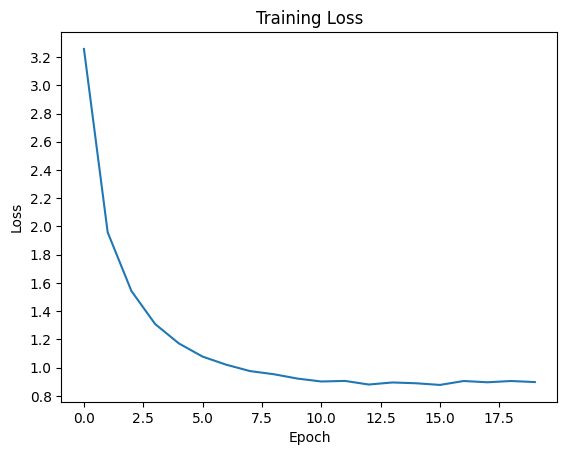

In [18]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
%matplotlib inline

def show_plot(points):
    plt.figure()
    fig, ax = plt.subplots()
    loc = ticker.MultipleLocator(base=0.2) # put ticks at regular intervals
    ax.yaxis.set_major_locator(loc)
    plt.plot(points)
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Training Loss')

show_plot(avg_losses)

In [38]:
def evaluate_batch(encoder, decoder, sentences, input_lang, output_lang, max_length=MAX_LENGTH):
    encoder.eval()
    decoder.eval()
    batch_size = len(sentences)
    print(f'batch_size={batch_size}')

    # 准备输入
    input_seqs = [input_lang.indexes_from_sentence(s) + [EOS_token] for s in sentences]
    src_lengths = [len(seq) for seq in input_seqs]
    max_src_len = max(src_lengths)
    input_batch = torch.zeros(batch_size, max_src_len, dtype=torch.long)
    for i, seq in enumerate(input_seqs):
        input_batch[i, :len(seq)] = torch.tensor(seq)
    if USE_CUDA:
        input_batch = input_batch.cuda()
    src_lengths_tensor = torch.tensor(src_lengths).cpu()

    with torch.no_grad():
        # 编码
        encoder_hidden = encoder.init_hidden(batch_size)
        encoder_outputs, encoder_hidden = encoder(input_batch, src_lengths_tensor, encoder_hidden)

        # 解码器初始隐藏状态
        decoder_hidden = encoder_hidden[-2:, :, :].sum(dim=0, keepdim=True)
        decoder_hidden = decoder_hidden.repeat(decoder.n_layers, 1, 1)

        decoder_input = torch.full((batch_size, 1), SOS_token, dtype=torch.long, device=input_batch.device)
        finished = [False] * batch_size
        outputs = [[] for _ in range(batch_size)]

        for _ in range(max_length):
            decoder_output, decoder_hidden = decoder(decoder_input, decoder_hidden,
                                                     encoder_outputs, src_lengths_tensor)
            topv, topi = decoder_output.topk(1)          # (batch,1)
            predicted = topi.squeeze(1)                  # (batch,)
            for b in range(batch_size):
                if finished[b]:
                    continue
                idx = predicted[b].item()
                if idx == EOS_token:
                    finished[b] = True
                else:
                    outputs[b].append(output_lang.index2word[idx])
            if all(finished):
                break
            decoder_input = predicted.unsqueeze(1)       # (batch,1)

    return [' '.join(out) for out in outputs]


In [47]:
def evaluate_randomly(pairs):
    pair = random.choice(pairs)
    
    output_sentence = evaluate_batch(encoder, decoder, [pair[0]], input_lang, output_lang)[0]
    
    print('>', pair[0])
    print('=', pair[1])
    print('<', output_sentence)
    print('')

print("====== 随机训练集 ======")
evaluate_randomly(train_pairs)

print("\n====== 随机验证集 ======")
evaluate_randomly(val_pairs)

====== 随机训练集 ======
batch_size=1
> 我已经不带眼镜了。
= i don t wear glasses anymore .
< i don t wear glasses anymore .


====== 随机验证集 ======
batch_size=1
> 你数学好吗？
= are you good in math ?
< are you good at mathematics ?



In [43]:
s_src = ['你看到什麼拿什麼。']
s_tgt = evaluate_batch(encoder, decoder, s_src, input_lang, output_lang)
print(s_tgt)

batch_size=1
['what what you get over .']


In [25]:
from nltk.translate.bleu_score import sentence_bleu, corpus_bleu
from nltk.translate.bleu_score import SmoothingFunction
import numpy as np

def calculate_bleu(references, hypotheses):
    """
    计算BLEU分数
    
    Args:
        references: 参考译文列表，每个元素是参考句子的分词列表
        hypotheses: 模型预测的译文列表，每个元素是预测句子的分词列表
    """
    # 使用平滑函数处理短句子
    smoothie = SmoothingFunction().method4
    
    # 计算句子级别的BLEU
    sentence_bleu_scores = []
    for ref, hyp in zip(references, hypotheses):
        # 注意：sentence_bleu的reference需要是列表的列表
        score = sentence_bleu([ref], hyp, 
                              weights=(0.25, 0.25, 0.25, 0.25),
                              smoothing_function=smoothie)
        sentence_bleu_scores.append(score)
    
    # 计算语料库级别的BLEU
    corpus_bleu_score = corpus_bleu([[ref] for ref in references], 
                                    hypotheses,
                                    smoothing_function=smoothie)
    
    return {
        'corpus_bleu': corpus_bleu_score,
        'mean_sentence_bleu': np.mean(sentence_bleu_scores),
        'sentence_bleus': sentence_bleu_scores
    }

In [31]:
src_setences = [pair[0] for pair in val_pairs]
references = [pair[1] for pair in val_pairs]  # 参考译文
hypotheses = evaluate_batch(encoder, decoder, src_setences, input_lang, output_lang)  # 模型预测    

bleu_scores = calculate_bleu(references, hypotheses)
print(f"Corpus BLEU: {bleu_scores['corpus_bleu']:.4f}")
print(f"Avarage Sentence BLEU: {bleu_scores['mean_sentence_bleu']:.4f}")

Corpus BLEU: 0.7496
Avarage Sentence BLEU: 0.7137


In [34]:
def translate_file(encoder, decoder, input_file, output_file):
    """
    读取txt文件中的原文，批量翻译，保存原文和翻译结果
    
    Args:
        encoder: 编码器模型
        decoder: 解码器模型
        input_file: 输入的原文文件路径
        output_file: 输出的翻译结果文件路径
    """
    
    print("=" * 70)
    print("文件批量翻译")
    print("=" * 70)
    
    # 1. 读取所有句子
    with open(input_file, 'r', encoding='utf-8') as f:
        all_sentences = [normalize_string(line).strip() for line in f if line.strip()]
    
    print(f"\n📖 读取到 {len(all_sentences)} 个句子")
    

    # 4. 批量翻译
    print(f"\n🔄 开始翻译...")
    start_time = time.time()
    
    translations = evaluate_batch(encoder, decoder, all_sentences, input_lang, output_lang)
        
    elapsed_time = time.time() - start_time
    print(f"✅ 翻译完成！用时: {elapsed_time:.2f} 秒")
    print(f"   平均每句: {elapsed_time/len(all_sentences):.3f} 秒")
    
    # 5. 保存结果
    print(f"\n💾 保存翻译结果到: {output_file}")
    
    with open(output_file, 'w', encoding='utf-8') as f:
        # 写入翻译结果
        for src, trans in zip(all_sentences, translations):
            f.write(f"{src}\t{trans}\n")
    
    print(f"✅ 成功保存 {len(translations)} 条翻译结果")


    
    # 7. 显示翻译预览
    print("\n📝 翻译预览 (前5行):")
    for i, (src, trans) in enumerate(zip(all_sentences[:5], translations[:5])):
        print(f"  {i+1}. {src} -> {trans}")
    
    print("\n" + "=" * 70)
    print(f"处理完成！")
    print(f"输入文件: {input_file}")
    print(f"输出文件: {output_file}")
    print("=" * 70)
    
    return
    

In [35]:
INPUT_FILE='test.txt'
OUTPUT_FILE='test_translations_batch.txt'

translate_file(encoder, decoder, input_file=INPUT_FILE, output_file=OUTPUT_FILE)

文件批量翻译

📖 读取到 9688 个句子

🔄 开始翻译...
✅ 翻译完成！用时: 3.41 秒
   平均每句: 0.000 秒

💾 保存翻译结果到: test_translations_batch.txt
✅ 成功保存 9688 条翻译结果

📝 翻译预览 (前5行):
  1. 為什麼我一直學不好英語？ -> why don t i english english ?
  2. 她讓我坐在她的身邊。 -> she kept me to her sit .
  3. 這瓶酸奶不含乳糖。 -> this bottle does yogurt not contain lactose lactose .
  4. 這瓶酸奶不含乳糖。 -> this bottle does yogurt not contain lactose lactose .
  5. 我不能幫你了。 -> i can t help you .

处理完成！
输入文件: test.txt
输出文件: test_translations_batch.txt


#### 调整超参数，重新批量训练

In [16]:
# ---------- 超参数 ----------
hidden_size = 512          # 增大(double)
n_layers = 2              
dropout = 0.2              # 增大(double)
learning_rate = 0.001
batch_size = 32
n_epochs = 10
clip = 5.0
teacher_forcing_ratio = 0.5

# ---------- 划分训练集和验证集（已划分好）----------
print(f"训练集: {len(train_pairs)} 句对, 验证集: {len(val_pairs)} 句对")

# ---------- 实例化模型 ----------
encoder = EncoderBiGRU(input_lang.n_words, hidden_size, n_layers, dropout)
decoder = DecoderAttnGRU(hidden_size, output_lang.n_words, n_layers, dropout)
if USE_CUDA:
    encoder = encoder.cuda()
    decoder = decoder.cuda()

# ---------- 训练 ----------
def train_model(encoder, decoder, train_pairs, val_pairs, n_epochs=20, batch_size=32,
                learning_rate=0.001, clip=5.0, teacher_forcing_ratio=0.5,
                save_path='seq2seq_model_batch'):
    
    encoder_optimizer = torch.optim.Adam(encoder.parameters(), lr=learning_rate)
    decoder_optimizer = torch.optim.Adam(decoder.parameters(), lr=learning_rate)
    criterion = nn.NLLLoss(ignore_index=0, reduction='none')  # PAD=0

    avg_losses = []
    for epoch in range(n_epochs):
        random.shuffle(train_pairs)
        total_loss = 0
        total_tokens = 0
        for i in range(0, len(train_pairs), batch_size):
            batch_pairs = train_pairs[i:i+batch_size]
            input_batch, target_batch = prepare_batch(batch_pairs, input_lang, output_lang)
            loss = train_one_batch(input_batch, target_batch, encoder, decoder,
                                   encoder_optimizer, decoder_optimizer, criterion,
                                   clip, teacher_forcing_ratio)
            total_loss += loss * (target_batch != 0).sum().item()
            total_tokens += (target_batch != 0).sum().item()
        avg_loss = total_loss / total_tokens
        avg_losses.append(avg_loss)
        print(f"Epoch {epoch+1}, Loss: {avg_loss:.4f}")

        # # 可选：在验证集上评估 BLEU
        # if (epoch+1) % 5 == 0:
        #     val_hyp = evaluate_batch(encoder, decoder, [p[0] for p in val_pairs], input_lang, output_lang)
        #     # 计算 BLEU 分数...
        
        
        # 保存模型
        if save_path and (epoch+1) % 10 == 0:
            torch.save({
                'epoch': epoch,
                'encoder_state_dict': encoder.state_dict(),
                'decoder_state_dict': decoder.state_dict(),
                'encoder_optimizer': encoder_optimizer.state_dict(),
                'decoder_optimizer': decoder_optimizer.state_dict(),
                'avg_losses': avg_losses,
            }, f'{save_path}_epoch{epoch}.pt')
    
    return encoder, decoder, avg_losses


# 开始训练
encoder, decoder, avg_losses = train_model(
    encoder, decoder, train_pairs, val_pairs,
    n_epochs=n_epochs, batch_size=batch_size,
    learning_rate=learning_rate, clip=clip,
    teacher_forcing_ratio=teacher_forcing_ratio,
    save_path='seq2seq_model_batch2'
)

训练集: 62009 句对, 验证集: 6889 句对
Epoch 1, Loss: 3.1576
Epoch 2, Loss: 1.9607
Epoch 3, Loss: 1.6228
Epoch 4, Loss: 1.4526
Epoch 5, Loss: 1.3756
Epoch 6, Loss: 1.3279
Epoch 7, Loss: 1.3159
Epoch 8, Loss: 1.3108
Epoch 9, Loss: 1.3030
Epoch 10, Loss: 1.2884


<Figure size 640x480 with 0 Axes>

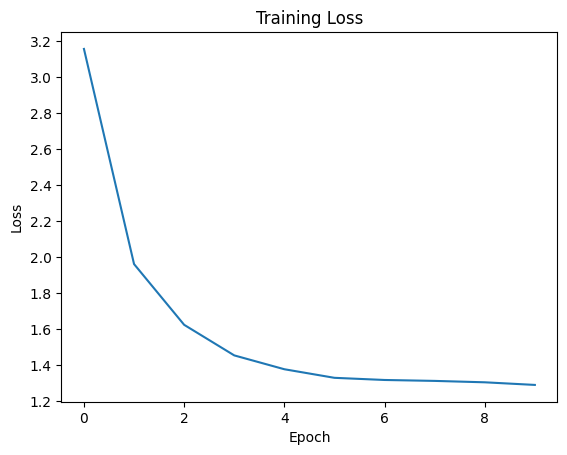

In [17]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
%matplotlib inline

def show_plot(points):
    plt.figure()
    fig, ax = plt.subplots()
    loc = ticker.MultipleLocator(base=0.2) # put ticks at regular intervals
    ax.yaxis.set_major_locator(loc)
    plt.plot(points)
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Training Loss')

show_plot(avg_losses)

In [18]:
def evaluate_batch(encoder, decoder, sentences, input_lang, output_lang, max_length=MAX_LENGTH):
    encoder.eval()
    decoder.eval()
    batch_size = len(sentences)
    print(f'batch_size={batch_size}')

    # 准备输入
    input_seqs = [input_lang.indexes_from_sentence(s) + [EOS_token] for s in sentences]
    src_lengths = [len(seq) for seq in input_seqs]
    max_src_len = max(src_lengths)
    input_batch = torch.zeros(batch_size, max_src_len, dtype=torch.long)
    for i, seq in enumerate(input_seqs):
        input_batch[i, :len(seq)] = torch.tensor(seq)
    if USE_CUDA:
        input_batch = input_batch.cuda()
    src_lengths_tensor = torch.tensor(src_lengths).cpu()

    with torch.no_grad():
        # 编码
        encoder_hidden = encoder.init_hidden(batch_size)
        encoder_outputs, encoder_hidden = encoder(input_batch, src_lengths_tensor, encoder_hidden)

        # 解码器初始隐藏状态
        decoder_hidden = encoder_hidden[-2:, :, :].sum(dim=0, keepdim=True)
        decoder_hidden = decoder_hidden.repeat(decoder.n_layers, 1, 1)

        decoder_input = torch.full((batch_size, 1), SOS_token, dtype=torch.long, device=input_batch.device)
        finished = [False] * batch_size
        outputs = [[] for _ in range(batch_size)]

        for _ in range(max_length):
            decoder_output, decoder_hidden = decoder(decoder_input, decoder_hidden,
                                                     encoder_outputs, src_lengths_tensor)
            topv, topi = decoder_output.topk(1)          # (batch,1)
            predicted = topi.squeeze(1)                  # (batch,)
            for b in range(batch_size):
                if finished[b]:
                    continue
                idx = predicted[b].item()
                if idx == EOS_token:
                    finished[b] = True
                else:
                    outputs[b].append(output_lang.index2word[idx])
            if all(finished):
                break
            decoder_input = predicted.unsqueeze(1)       # (batch,1)

    return [' '.join(out) for out in outputs]


In [19]:
def evaluate_randomly(pairs):
    pair = random.choice(pairs)
    
    output_sentence = evaluate_batch(encoder, decoder, [pair[0]], input_lang, output_lang)[0]
    
    print('>', pair[0])
    print('=', pair[1])
    print('<', output_sentence)
    print('')

print("====== 随机训练集 ======")
evaluate_randomly(train_pairs)

print("\n====== 随机验证集 ======")
evaluate_randomly(val_pairs)

====== 随机训练集 ======
batch_size=1
> 你最喜欢的饮料是什么？
= what s your favorite drink ?
< what s your favorite ipad app ?


====== 随机验证集 ======
batch_size=1
> 没消息就是好消息。
= no news is good news .
< no news is good news .



In [20]:
from nltk.translate.bleu_score import sentence_bleu, corpus_bleu
from nltk.translate.bleu_score import SmoothingFunction
import numpy as np

def calculate_bleu(references, hypotheses):
    """
    计算BLEU分数
    
    Args:
        references: 参考译文列表，每个元素是参考句子的分词列表
        hypotheses: 模型预测的译文列表，每个元素是预测句子的分词列表
    """
    # 使用平滑函数处理短句子
    smoothie = SmoothingFunction().method4
    
    # 计算句子级别的BLEU
    sentence_bleu_scores = []
    for ref, hyp in zip(references, hypotheses):
        # 注意：sentence_bleu的reference需要是列表的列表
        score = sentence_bleu([ref], hyp, 
                              weights=(0.25, 0.25, 0.25, 0.25),
                              smoothing_function=smoothie)
        sentence_bleu_scores.append(score)
    
    # 计算语料库级别的BLEU
    corpus_bleu_score = corpus_bleu([[ref] for ref in references], 
                                    hypotheses,
                                    smoothing_function=smoothie)
    
    return {
        'corpus_bleu': corpus_bleu_score,
        'mean_sentence_bleu': np.mean(sentence_bleu_scores),
        'sentence_bleus': sentence_bleu_scores
    }

src_setences = [pair[0] for pair in val_pairs]
references = [pair[1] for pair in val_pairs]  # 参考译文
hypotheses = evaluate_batch(encoder, decoder, src_setences, input_lang, output_lang)  # 模型预测    

bleu_scores = calculate_bleu(references, hypotheses)
print(f"Corpus BLEU: {bleu_scores['corpus_bleu']:.4f}")
print(f"Avarage Sentence BLEU: {bleu_scores['mean_sentence_bleu']:.4f}")

batch_size=6889
Corpus BLEU: 0.6840
Avarage Sentence BLEU: 0.6450


继续训练

In [15]:
# ---------- 超参数 ----------
hidden_size = 512          
n_layers = 2              
dropout = 0.2             
learning_rate = 0.001
batch_size = 32
n_epochs = 20              # 继续训练10个epoch
clip = 5.0
teacher_forcing_ratio = 0.5

def load_checkpoint(checkpoint_path, encoder, decoder, optimizer_encoder=None, optimizer_decoder=None):
    """
    加载模型检查点。
    
    Args:
        checkpoint_path: 保存的pt文件路径
        encoder: EncoderBiGRU 实例
        decoder: DecoderAttnGRU 实例
        optimizer_encoder: 编码器优化器（如需恢复训练则传入）
        optimizer_decoder: 解码器优化器（如需恢复训练则传入）
    
    Returns:
        start_epoch: 已训练的epoch数（下一个要开始的epoch）
        avg_losses: 历史损失列表
    """
    checkpoint = torch.load(checkpoint_path, map_location=torch.device('cuda' if USE_CUDA else 'cpu'))
    
    encoder.load_state_dict(checkpoint['encoder_state_dict'])
    decoder.load_state_dict(checkpoint['decoder_state_dict'])
    
    if optimizer_encoder is not None and optimizer_decoder is not None:
        optimizer_encoder.load_state_dict(checkpoint['encoder_optimizer'])
        optimizer_decoder.load_state_dict(checkpoint['decoder_optimizer'])
    
    start_epoch = checkpoint.get('epoch', 0) + 1   # 已完成的epoch数，下一个epoch从+1开始
    avg_losses = checkpoint.get('avg_losses', [])
    
    print(f"Loaded checkpoint from {checkpoint_path}, epoch={checkpoint.get('epoch', 0)}, loss={avg_losses[-1] if avg_losses else 'N/A'}")
    return start_epoch, avg_losses

encoder = EncoderBiGRU(input_lang.n_words, hidden_size, n_layers, dropout)
decoder = DecoderAttnGRU(hidden_size, output_lang.n_words, n_layers, dropout)
if USE_CUDA:
    encoder = encoder.cuda()
    decoder = decoder.cuda()
encoder_optimizer = torch.optim.Adam(encoder.parameters(), lr=learning_rate)
decoder_optimizer = torch.optim.Adam(decoder.parameters(), lr=learning_rate)
checkpoint_path = 'seq2seq_model_batch2_epoch9.pt'
start_epoch, avg_losses = load_checkpoint(
    checkpoint_path, encoder, decoder,
    encoder_optimizer, decoder_optimizer
)

Loaded checkpoint from seq2seq_model_batch2_epoch9.pt, epoch=9, loss=1.2883965022046624


In [16]:
start_epoch

10

In [17]:
def train_model(encoder, decoder, train_pairs, val_pairs, n_epochs=20, batch_size=32,
                learning_rate=0.001, clip=5.0, teacher_forcing_ratio=0.5,
                save_path='seq2seq_model_batch'):
    
    encoder_optimizer = torch.optim.Adam(encoder.parameters(), lr=learning_rate)
    decoder_optimizer = torch.optim.Adam(decoder.parameters(), lr=learning_rate)
    criterion = nn.NLLLoss(ignore_index=0, reduction='none')  # PAD=0

    avg_losses = []
    for epoch in range(start_epoch, n_epochs):
        random.shuffle(train_pairs)
        total_loss = 0
        total_tokens = 0
        for i in range(0, len(train_pairs), batch_size):
            batch_pairs = train_pairs[i:i+batch_size]
            input_batch, target_batch = prepare_batch(batch_pairs, input_lang, output_lang)
            loss = train_one_batch(input_batch, target_batch, encoder, decoder,
                                   encoder_optimizer, decoder_optimizer, criterion,
                                   clip, teacher_forcing_ratio)
            total_loss += loss * (target_batch != 0).sum().item()
            total_tokens += (target_batch != 0).sum().item()
        avg_loss = total_loss / total_tokens
        avg_losses.append(avg_loss)
        print(f"Epoch {epoch+1}, Loss: {avg_loss:.4f}")

        # # 可选：在验证集上评估 BLEU
        # if (epoch+1) % 5 == 0:
        #     val_hyp = evaluate_batch(encoder, decoder, [p[0] for p in val_pairs], input_lang, output_lang)
        #     # 计算 BLEU 分数...
        
        
        # 保存模型
        if save_path and (epoch+1) % 10 == 0:
            torch.save({
                'epoch': epoch,
                'encoder_state_dict': encoder.state_dict(),
                'decoder_state_dict': decoder.state_dict(),
                'encoder_optimizer': encoder_optimizer.state_dict(),
                'decoder_optimizer': decoder_optimizer.state_dict(),
                'avg_losses': avg_losses,
            }, f'{save_path}_epoch{epoch}.pt')
    
    return encoder, decoder, avg_losses

# 开始训练
encoder, decoder, avg_losses = train_model(
    encoder, decoder, train_pairs, val_pairs,
    n_epochs=n_epochs, batch_size=batch_size,
    learning_rate=learning_rate, clip=clip,
    teacher_forcing_ratio=teacher_forcing_ratio,
    save_path='seq2seq_model_batch2'
)

Epoch 11, Loss: 1.3410
Epoch 12, Loss: 1.3059
Epoch 13, Loss: 1.3137
Epoch 14, Loss: 1.3069
Epoch 15, Loss: 1.3247
Epoch 16, Loss: 1.3230
Epoch 17, Loss: 1.3455
Epoch 18, Loss: 1.3570
Epoch 19, Loss: 1.3574
Epoch 20, Loss: 1.3508


<Figure size 640x480 with 0 Axes>

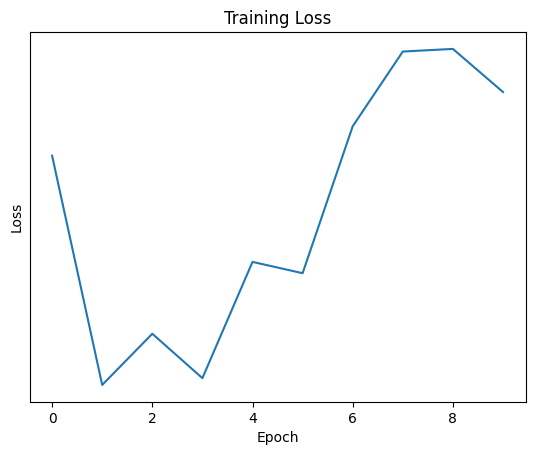

In [18]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
%matplotlib inline

def show_plot(points):
    plt.figure()
    fig, ax = plt.subplots()
    loc = ticker.MultipleLocator(base=0.2) # put ticks at regular intervals
    ax.yaxis.set_major_locator(loc)
    plt.plot(points)
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Training Loss')

show_plot(avg_losses)

In [19]:
def evaluate_batch(encoder, decoder, sentences, input_lang, output_lang, max_length=MAX_LENGTH):
    encoder.eval()
    decoder.eval()
    batch_size = len(sentences)
    print(f'batch_size={batch_size}')

    # 准备输入
    input_seqs = [input_lang.indexes_from_sentence(s) + [EOS_token] for s in sentences]
    src_lengths = [len(seq) for seq in input_seqs]
    max_src_len = max(src_lengths)
    input_batch = torch.zeros(batch_size, max_src_len, dtype=torch.long)
    for i, seq in enumerate(input_seqs):
        input_batch[i, :len(seq)] = torch.tensor(seq)
    if USE_CUDA:
        input_batch = input_batch.cuda()
    src_lengths_tensor = torch.tensor(src_lengths).cpu()

    with torch.no_grad():
        # 编码
        encoder_hidden = encoder.init_hidden(batch_size)
        encoder_outputs, encoder_hidden = encoder(input_batch, src_lengths_tensor, encoder_hidden)

        # 解码器初始隐藏状态
        decoder_hidden = encoder_hidden[-2:, :, :].sum(dim=0, keepdim=True)
        decoder_hidden = decoder_hidden.repeat(decoder.n_layers, 1, 1)

        decoder_input = torch.full((batch_size, 1), SOS_token, dtype=torch.long, device=input_batch.device)
        finished = [False] * batch_size
        outputs = [[] for _ in range(batch_size)]

        for _ in range(max_length):
            decoder_output, decoder_hidden = decoder(decoder_input, decoder_hidden,
                                                     encoder_outputs, src_lengths_tensor)
            topv, topi = decoder_output.topk(1)          # (batch,1)
            predicted = topi.squeeze(1)                  # (batch,)
            for b in range(batch_size):
                if finished[b]:
                    continue
                idx = predicted[b].item()
                if idx == EOS_token:
                    finished[b] = True
                else:
                    outputs[b].append(output_lang.index2word[idx])
            if all(finished):
                break
            decoder_input = predicted.unsqueeze(1)       # (batch,1)

    return [' '.join(out) for out in outputs]


In [20]:
from nltk.translate.bleu_score import sentence_bleu, corpus_bleu
from nltk.translate.bleu_score import SmoothingFunction
import numpy as np

def calculate_bleu(references, hypotheses):
    """
    计算BLEU分数
    
    Args:
        references: 参考译文列表，每个元素是参考句子的分词列表
        hypotheses: 模型预测的译文列表，每个元素是预测句子的分词列表
    """
    # 使用平滑函数处理短句子
    smoothie = SmoothingFunction().method4
    
    # 计算句子级别的BLEU
    sentence_bleu_scores = []
    for ref, hyp in zip(references, hypotheses):
        # 注意：sentence_bleu的reference需要是列表的列表
        score = sentence_bleu([ref], hyp, 
                              weights=(0.25, 0.25, 0.25, 0.25),
                              smoothing_function=smoothie)
        sentence_bleu_scores.append(score)
    
    # 计算语料库级别的BLEU
    corpus_bleu_score = corpus_bleu([[ref] for ref in references], 
                                    hypotheses,
                                    smoothing_function=smoothie)
    
    return {
        'corpus_bleu': corpus_bleu_score,
        'mean_sentence_bleu': np.mean(sentence_bleu_scores),
        'sentence_bleus': sentence_bleu_scores
    }

src_setences = [pair[0] for pair in val_pairs]
references = [pair[1] for pair in val_pairs]  # 参考译文
hypotheses = evaluate_batch(encoder, decoder, src_setences, input_lang, output_lang)  # 模型预测    

bleu_scores = calculate_bleu(references, hypotheses)
print(f"Corpus BLEU: {bleu_scores['corpus_bleu']:.4f}")
print(f"Avarage Sentence BLEU: {bleu_scores['mean_sentence_bleu']:.4f}")

batch_size=6889
Corpus BLEU: 0.6776
Avarage Sentence BLEU: 0.6377


#### Beam Search

In [18]:
def evaluate_batch_beam(encoder, decoder, sentences, input_lang, output_lang,
                        beam_width=5, max_length=MAX_LENGTH):
    encoder.eval()
    decoder.eval()
    batch_size = len(sentences)

    # 准备输入张量
    input_seqs = [input_lang.indexes_from_sentence(s) + [EOS_token] for s in sentences]
    src_lengths = [len(seq) for seq in input_seqs]
    max_src_len = max(src_lengths)
    input_batch = torch.zeros(batch_size, max_src_len, dtype=torch.long)
    for i, seq in enumerate(input_seqs):
        input_batch[i, :len(seq)] = torch.tensor(seq)
    if USE_CUDA:
        input_batch = input_batch.cuda()
    src_lengths_tensor = torch.tensor(src_lengths).cpu()

    with torch.no_grad():
        encoder_hidden = encoder.init_hidden(batch_size)
        encoder_outputs, encoder_hidden = encoder(input_batch, src_lengths_tensor, encoder_hidden)
        # encoder_outputs: (batch, max_src_len, hidden*2)
        # encoder_hidden: (n_layers*2, batch, hidden)

        all_translations = []
        for idx in range(batch_size):
            # 当前句子的编码器输出
            sent_enc_output = encoder_outputs[idx:idx+1, :, :]   # (1, src_len, hidden*2)
            # 当前句子的编码器最终隐藏状态（双向）
            sent_enc_hidden = encoder_hidden[:, idx:idx+1, :]    # (n_layers*2, 1, hidden)

            # 转换为解码器初始隐藏状态（单向）
            # 取最后两层（前向和后向）求和，得到 (1, 1, hidden)
            dec_hidden = sent_enc_hidden[-2:, :, :].sum(dim=0, keepdim=True)   # (1, 1, hidden)
            # 重复 n_layers 次（解码器层数）
            dec_hidden = dec_hidden.repeat(decoder.n_layers, 1, 1)             # (n_layers, 1, hidden)

            # 初始化 beams
            beams = [([SOS_token], 0.0, dec_hidden)]
            for _ in range(max_length):
                all_candidates = []
                for seq, score, hidden in beams:
                    if seq[-1] == EOS_token:
                        all_candidates.append((seq, score, hidden))
                        continue
                    dec_input = torch.LongTensor([[seq[-1]]]).to(input_batch.device)
                    dec_output, new_hidden = decoder(dec_input, hidden, sent_enc_output,
                                                     src_lengths_tensor[idx:idx+1])
                    log_probs = dec_output.squeeze(0)   # (vocab_size,)
                    top_log_probs, top_indices = log_probs.topk(beam_width)
                    for i in range(beam_width):
                        next_token = top_indices[i].item()
                        new_score = score + top_log_probs[i].item()
                        all_candidates.append((seq + [next_token], new_score, new_hidden))
                # 保留最佳 beam_width 个候选
                beams = sorted(all_candidates, key=lambda x: x[1], reverse=True)[:beam_width]
                if all(seq[-1] == EOS_token for seq, _, _ in beams):
                    break

            best_seq = beams[0][0]
            words = [output_lang.index2word[t] for t in best_seq if t not in (SOS_token, EOS_token)]
            all_translations.append(' '.join(words))

    return all_translations

In [15]:
def load_checkpoint(checkpoint_path, encoder, decoder, optimizer_encoder=None, optimizer_decoder=None):
    """
    加载模型检查点。
    
    Args:
        checkpoint_path: 保存的pt文件路径
        encoder: EncoderBiGRU 实例
        decoder: DecoderAttnGRU 实例
        optimizer_encoder: 编码器优化器（如需恢复训练则传入）
        optimizer_decoder: 解码器优化器（如需恢复训练则传入）
    
    Returns:
        start_epoch: 已训练的epoch数（下一个要开始的epoch）
        avg_losses: 历史损失列表
    """
    checkpoint = torch.load(checkpoint_path, map_location=torch.device('cuda' if USE_CUDA else 'cpu'))
    
    encoder.load_state_dict(checkpoint['encoder_state_dict'])
    decoder.load_state_dict(checkpoint['decoder_state_dict'])
    
    if optimizer_encoder is not None and optimizer_decoder is not None:
        optimizer_encoder.load_state_dict(checkpoint['encoder_optimizer'])
        optimizer_decoder.load_state_dict(checkpoint['decoder_optimizer'])
    
    start_epoch = checkpoint.get('epoch', 0) + 1   # 已完成的epoch数，下一个epoch从+1开始
    avg_losses = checkpoint.get('avg_losses', [])
    
    print(f"Loaded checkpoint from {checkpoint_path}, epoch={checkpoint.get('epoch', 0)}, loss={avg_losses[-1] if avg_losses else 'N/A'}")
    return start_epoch, avg_losses


In [16]:
# ---------- 超参数 ----------
hidden_size = 256          # 隐藏层维度，可根据需要调整
n_layers = 2               # RNN层数
dropout = 0.1              # Dropout比例

encoder = EncoderBiGRU(input_lang.n_words, hidden_size, n_layers, dropout)
decoder = DecoderAttnGRU(hidden_size, output_lang.n_words, n_layers, dropout)
if USE_CUDA:
    encoder = encoder.cuda()
    decoder = decoder.cuda()

checkpoint_path = 'seq2seq_model_batch_epoch19.pt'
_, avg_losses = load_checkpoint(checkpoint_path, encoder, decoder)  # 不传入优化器
encoder.eval()
decoder.eval()


Loaded checkpoint from seq2seq_model_batch_epoch19.pt, epoch=19, loss=0.8979318618902816


DecoderAttnGRU(
  (embedding): Embedding(8855, 256)
  (gru): GRU(256, 256, num_layers=2, batch_first=True, dropout=0.1)
  (attn_linear): Linear(in_features=256, out_features=512, bias=True)
  (out): Linear(in_features=768, out_features=8855, bias=True)
  (dropout): Dropout(p=0.1, inplace=False)
)

In [19]:
from nltk.translate.bleu_score import sentence_bleu, corpus_bleu
from nltk.translate.bleu_score import SmoothingFunction
import numpy as np

def calculate_bleu(references, hypotheses):
    """
    计算BLEU分数
    
    Args:
        references: 参考译文列表，每个元素是参考句子的分词列表
        hypotheses: 模型预测的译文列表，每个元素是预测句子的分词列表
    """
    # 使用平滑函数处理短句子
    smoothie = SmoothingFunction().method4
    
    # 计算句子级别的BLEU
    sentence_bleu_scores = []
    for ref, hyp in zip(references, hypotheses):
        # 注意：sentence_bleu的reference需要是列表的列表
        score = sentence_bleu([ref], hyp, 
                              weights=(0.25, 0.25, 0.25, 0.25),
                              smoothing_function=smoothie)
        sentence_bleu_scores.append(score)
    
    # 计算语料库级别的BLEU
    corpus_bleu_score = corpus_bleu([[ref] for ref in references], 
                                    hypotheses,
                                    smoothing_function=smoothie)
    
    return {
        'corpus_bleu': corpus_bleu_score,
        'mean_sentence_bleu': np.mean(sentence_bleu_scores),
        'sentence_bleus': sentence_bleu_scores
    }

src_setences = [pair[0] for pair in val_pairs]
references = [pair[1] for pair in val_pairs]  # 参考译文
hypotheses = evaluate_batch_beam(encoder, decoder, src_setences, input_lang, output_lang, beam_width=5)  # 使用beam search    

bleu_scores = calculate_bleu(references, hypotheses)
print(f"Corpus BLEU: {bleu_scores['corpus_bleu']:.4f}")
print(f"Avarage Sentence BLEU: {bleu_scores['mean_sentence_bleu']:.4f}")

Corpus BLEU: 0.7684
Avarage Sentence BLEU: 0.7362


In [20]:
def translate_file(encoder, decoder, input_file, output_file):
    """
    读取txt文件中的原文，批量翻译，保存原文和翻译结果
    
    Args:
        encoder: 编码器模型
        decoder: 解码器模型
        input_file: 输入的原文文件路径
        output_file: 输出的翻译结果文件路径
    """
    
    print("=" * 70)
    print("文件批量翻译")
    print("=" * 70)
    
    # 1. 读取所有句子
    with open(input_file, 'r', encoding='utf-8') as f:
        all_sentences = [normalize_string(line).strip() for line in f if line.strip()]
    
    print(f"\n📖 读取到 {len(all_sentences)} 个句子")
    

    # 2. 批量翻译
    print(f"\n🔄 开始翻译...")
    start_time = time.time()
    
    translations = evaluate_batch_beam(encoder, decoder, all_sentences, input_lang, output_lang, beam_width=5)  # 使用beam search    
        
    elapsed_time = time.time() - start_time
    print(f"✅ 翻译完成！用时: {elapsed_time:.2f} 秒")
    print(f"   平均每句: {elapsed_time/len(all_sentences):.3f} 秒")
    
    # 3. 保存结果
    print(f"\n💾 保存翻译结果到: {output_file}")
    
    with open(output_file, 'w', encoding='utf-8') as f:
        # 写入翻译结果
        for src, trans in zip(all_sentences, translations):
            f.write(f"{src}\t{trans}\n")
    
    print(f"✅ 成功保存 {len(translations)} 条翻译结果")

 
    # 4. 显示翻译预览
    print("\n📝 翻译预览 (前5行):")
    for i, (src, trans) in enumerate(zip(all_sentences[:5], translations[:5])):
        print(f"  {i+1}. {src} -> {trans}")
    
    print("\n" + "=" * 70)
    print(f"处理完成！")
    print(f"输入文件: {input_file}")
    print(f"输出文件: {output_file}")
    print("=" * 70)
    
    return

INPUT_FILE='test.txt'
OUTPUT_FILE='test_translations_batch_beam.txt'

translate_file(encoder, decoder, input_file=INPUT_FILE, output_file=OUTPUT_FILE)

文件批量翻译

📖 读取到 9688 个句子

🔄 开始翻译...
✅ 翻译完成！用时: 657.51 秒
   平均每句: 0.068 秒

💾 保存翻译结果到: test_translations_batch_beam.txt
✅ 成功保存 9688 条翻译结果

📝 翻译预览 (前5行):
  1. 為什麼我一直學不好英語？ -> why don t i make english english ?
  2. 她讓我坐在她的身邊。 -> she kept me to her sit .
  3. 這瓶酸奶不含乳糖。 -> this bottle of yogurt does not contain lactose .
  4. 這瓶酸奶不含乳糖。 -> this bottle of yogurt does not contain lactose .
  5. 我不能幫你了。 -> i can t help you .

处理完成！
输入文件: test.txt
输出文件: test_translations_batch_beam.txt
